# Explainable Multimodal Pneumonia Detection: analysis notebook (v2)

**Group:** Fatima Siddiqa (23i-2543), Mariam Shaiq (23i-3250)

The sections follow the paper: data -> base model (image only) -> extended models (fusion)
-> main results -> robustness (seeds, nested models, subgroups) -> modality contribution
-> Grad-CAM localisation -> external validation (NIH) -> figures and LaTeX tables.

**Inputs to attach (Add Input):**
1. Competition `rsna-pneumonia-detection-challenge` (DICOM images)
2. Your private dataset with `labels.csv` and `boxes.csv` (made by `prepare_labels.py`)
3. Dataset `nih-chest-xrays/data` (external validation, Section 10)

**Settings:** Accelerator GPU T4, Internet ON. Run with *Save Version -> Save & Run All*.
Expected run time: about 3 hours (9 training runs of ~16 min + caching + evaluation).
All outputs land in `/kaggle/working` (`figures/`, `tables/`, CSVs, model weights).

In [1]:
import glob
import json
import os
import random
import time

import cv2
import matplotlib
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
import torch
import torch.nn as nn
import torch.nn.functional as F
from joblib import Parallel, delayed
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

SEEDS = [42, 7, 123]      # 42 = primary run (main tables); 7 and 123 = robustness re-runs
PRIMARY = 42
IMG, BATCH, EPOCHS, LR = 224, 32, 8, 1e-4
N_BOOT = 5000             # patient-level bootstrap resamples
ALPHA = 0.05              # significance level
WORK = "/kaggle/working"
FIG, TEX = f"{WORK}/figures", f"{WORK}/tables"
os.makedirs(FIG, exist_ok=True)
os.makedirs(TEX, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


set_seed(PRIMARY)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Figure style: one serif font, 400 DPI, white background, recessive axes
plt.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "figure.facecolor": "white", "savefig.facecolor": "white", "lines.linewidth": 2,
})
# Colour follows the model, in fixed order (validated categorical slots 1-3); metadata baselines are grey
COLOR = {"image": "#2a78d6", "fusion_as": "#eb6834", "fusion_asv": "#1baf7a",
         "tab_only_as": "#a3a29c", "tab_only_asv": "#52514e"}
NAME = {"image": "Image only (base)", "fusion_as": "Fusion: image + age + sex",
        "fusion_asv": "Fusion: image + age + sex + view",
        "tab_only_as": "Metadata: age + sex", "tab_only_asv": "Metadata: age + sex + view"}


def savefig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=400, bbox_inches="tight")
    fig.savefig(f"{FIG}/{name}.pdf", bbox_inches="tight")
    plt.show()

device: cuda Tesla T4
torch 2.11.0+cu130 | numpy 2.1.3 | pandas 2.3.3


## 1. Locate inputs and check the RSNA <-> NIH mapping

In [2]:
labels_path = glob.glob("/kaggle/input/**/labels.csv", recursive=True)
boxes_path = glob.glob("/kaggle/input/**/boxes.csv", recursive=True)
assert labels_path and boxes_path, "Attach the dataset with labels.csv and boxes.csv"
df = pd.read_csv(labels_path[0])
boxes = pd.read_csv(boxes_path[0])

dcm_index = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob("/kaggle/input/**/*.dcm", recursive=True)}
df["path"] = df.rsna_id.map(dcm_index)
print(f"DICOMs found: {len(dcm_index)}  labelled: {len(df)}  without DICOM: {df.path.isna().sum()}")
assert df.path.notna().all()

# The DICOM's own SOPInstanceUID must equal the one in our mapping (same image)
chk = df.sample(200, random_state=PRIMARY)
same = sum(pydicom.dcmread(p, stop_before_pixels=True).SOPInstanceUID == u for p, u in zip(chk.path, chk.SOPInstanceUID))
print(f"SOPInstanceUID match on 200 random files: {same}/200")
assert same == 200

df["age_n"] = df.age.clip(0, 100) / 100.0
df = df.reset_index(drop=True)
df["row"] = np.arange(len(df))

# Sample profile (Table: sample profile in the paper)
prof = []
for s in ["train", "val", "test"]:
    d = df[df.split == s]
    prof.append({"Split": s, "Images": len(d), "Patients": d.nih_patient_id.nunique(),
                 "Lung opacity (%)": 100 * d.target.mean(), "Age mean (SD)": f"{d.age.mean():.1f} ({d.age.std():.1f})",
                 "Male (%)": 100 * d.sex_m.mean(), "AP view (%)": 100 * d.view_ap.mean()})
profile = pd.DataFrame(prof).round(1)
profile

DICOMs found: 29684  labelled: 29684  without DICOM: 0
SOPInstanceUID match on 200 random files: 200/200


,Split,Images,Patients,Lung opacity (%),Age mean (SD),Male (%),AP view (%)
0,train,20401,8562,23.4,46.5 (16.8),56.9,44.9
1,val,4879,1834,25.4,47.2 (16.5),56.3,48.4
2,test,4404,1837,24.6,47.5 (16.6),57.3,46.0


## 2. Data screening: missing values, outliers, class balance, view/label association

In [3]:
print("Missing values per column:\n", df[["age", "sex", "view", "target"]].isna().sum().to_dict())
print("Age outside 1-95:", int(((df.age < 1) | (df.age > 95)).sum()), "images (kept; age is clipped to 0-100)")
print("\nClass counts:\n", df.label_name.value_counts().to_dict())
ct = pd.crosstab(df.view, df.target)
chi2, p_chi, _, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / len(df))
print(f"\nView x target: chi2={chi2:.1f}, p={p_chi:.2e}, Cramer's V={cramers_v:.3f}")
print(pd.crosstab(df.label_name, df.view, normalize="index").round(3))
SCREEN = {"chi2_view": chi2, "p_view": p_chi, "cramers_v": cramers_v}

Missing values per column:
 {'age': 0, 'sex': 0, 'view': 0, 'target': 0}
Age outside 1-95: 3 images (kept; age is clipped to 0-100)

Class counts:
 {'No Lung Opacity / Not Normal': 12788, 'Normal': 9790, 'Lung Opacity': 7106}

View x target: chi2=3763.6, p=0.00e+00, Cramer's V=0.356
view                             AP     PA
label_name                                
Lung Opacity                  0.773  0.227
No Lung Opacity / Not Normal  0.490  0.510
Normal                        0.183  0.817


## 3. Cache resized images (one-off, ~4 min)

In [4]:
CACHE = f"{WORK}/images_{IMG}.npy"
_prev_cache = glob.glob(f"/kaggle/input/**/images_{IMG}.npy", recursive=True)
if _prev_cache and not os.path.exists(CACHE):
    CACHE = _prev_cache[0]                      # reuse the cache from an earlier run attached as input
    print("Reusing image cache:", CACHE)


def to_uint8(a):
    a = a.astype(np.float32)
    a = (a - a.min()) / max(a.max() - a.min(), 1e-6) * 255
    return cv2.resize(a, (IMG, IMG), interpolation=cv2.INTER_AREA).astype(np.uint8)


def load_dicom(path):
    return to_uint8(pydicom.dcmread(path).pixel_array)


if not os.path.exists(CACHE):
    t = time.time()
    np.save(CACHE, np.stack(Parallel(n_jobs=4, batch_size=64)(delayed(load_dicom)(p) for p in df.path)))
    print(f"cached in {time.time() - t:.0f}s")
IMAGES = np.load(CACHE, mmap_mode="r")
print(IMAGES.shape)

Reusing image cache: /kaggle/input/notebooks/memoshine/notebook2abd899475/images_224.npy
(29684, 224, 224)


## 4. Dataset and model
Image branch: DenseNet-121 (ImageNet weights). Metadata branch: 2-layer MLP (32 units).
Fusion: concatenate the 1024-d image embedding with the 32-d metadata embedding, then a linear head.

In [5]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
AUG = transforms.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.95, 1.05))


class CXR(Dataset):
    def __init__(self, frame, tab_cols, train, images):
        self.rows = frame.row.to_numpy()
        self.y = frame.target.to_numpy().astype(np.float32)
        self.tab = frame[tab_cols].to_numpy().astype(np.float32) if tab_cols else np.zeros((len(frame), 0), np.float32)
        self.train, self.images = train, images

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        x = torch.from_numpy(np.array(self.images[self.rows[i]])).float().div(255).unsqueeze(0)
        if self.train:
            x = AUG(x)
        x = (x.repeat(3, 1, 1) - MEAN) / STD
        return x, torch.from_numpy(self.tab[i]), torch.tensor(self.y[i])


class Net(nn.Module):
    def __init__(self, n_tab):
        super().__init__()
        self.features = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1).features
        self.n_tab = n_tab
        d = 1024
        if n_tab:
            self.tab = nn.Sequential(nn.Linear(n_tab, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU())
            d += 32
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(d, 1))

    def forward(self, img, tab):
        f = F.adaptive_avg_pool2d(F.relu(self.features(img)), 1).flatten(1)
        if self.n_tab:
            f = torch.cat([f, self.tab(tab)], 1)
        return self.head(f).squeeze(1)


def make_loader(frame, cols, train=False, images=None, seed=PRIMARY):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(CXR(frame, cols, train, IMAGES if images is None else images),
                      BATCH if train else BATCH * 2, shuffle=train, drop_last=train,
                      num_workers=4, pin_memory=True, generator=g)


@torch.no_grad()
def predict(model, loader, occlude=None, tab_fill=None):
    """occlude: None | 'image' | 'tab' | int (one metadata column)."""
    model.eval()
    out = []
    for x, t, _ in loader:
        x, t = x.to(DEVICE), t.to(DEVICE)
        if occlude == "image":
            x = torch.zeros_like(x)                     # ImageNet-mean grey image
        elif occlude == "tab":
            t = tab_fill.expand_as(t).clone()           # training-set mean
        elif isinstance(occlude, int):
            t = t.clone()
            t[:, occlude] = tab_fill[0, occlude]
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            out.append(torch.sigmoid(model(x, t)).float().cpu())
    return torch.cat(out).numpy()


def train(name, cols, seed):
    set_seed(seed)
    tr = make_loader(df[df.split == "train"], cols, train=True, seed=seed)
    va = make_loader(df[df.split == "val"], cols)
    model = Net(len(cols)).to(DEVICE)
    ytr = df[df.split == "train"].target
    pos_w = torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), device=DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=EPOCHS * len(tr), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    yva = df[df.split == "val"].target.to_numpy()
    best, hist, ckpt = -1, [], f"{WORK}/{name}_s{seed}.pt"
    for ep in range(EPOCHS):
        model.train()
        t0, tot = time.time(), 0.0
        for x, t, y in tr:
            x, t, y = x.to(DEVICE), t.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                loss = F.binary_cross_entropy_with_logits(model(x, t), y, pos_weight=pos_w)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.item()
        auc = roc_auc_score(yva, predict(model, va))
        hist.append({"model": name, "seed": seed, "epoch": ep + 1, "train_loss": tot / len(tr), "val_auc": auc})
        print(f"[{name} s{seed}] epoch {ep + 1}/{EPOCHS} loss {tot / len(tr):.4f} val AUC {auc:.4f} ({time.time() - t0:.0f}s)")
        if auc > best:                                   # keep the best epoch on validation AUC
            best = auc
            torch.save(model.state_dict(), ckpt)
    model.load_state_dict(torch.load(ckpt))
    return model, hist

## 5. Metadata-only baselines (logistic regression)

In [6]:
SPLITS = {s: df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"]}
results = {}              # (model, seed) -> {"val": probs, "test": probs}
TAB_SETS = {"tab_only_as": ["age_n", "sex_m"], "tab_only_asv": ["age_n", "sex_m", "view_ap"]}
lr_models = {}
for name, cols in TAB_SETS.items():
    lr = LogisticRegression(max_iter=1000, class_weight="balanced")
    lr.fit(SPLITS["train"][cols], SPLITS["train"].target)
    lr_models[name] = lr
    results[(name, PRIMARY)] = {s: lr.predict_proba(SPLITS[s][cols])[:, 1] for s in ["val", "test"]}
    print(name, "coef:", dict(zip(cols, lr.coef_[0].round(3))),
          "test AUC", round(roc_auc_score(SPLITS["test"].target, results[(name, PRIMARY)]["test"]), 4))

tab_only_as coef: {'age_n': np.float64(-0.667), 'sex_m': np.float64(0.096)} test AUC 0.5826
tab_only_asv coef: {'age_n': np.float64(-0.373), 'sex_m': np.float64(0.088), 'view_ap': np.float64(1.773)} test AUC 0.7373


## 6. Train base and extended models for every seed (~16 min per run on a T4)
Nested models: image (base) -> + age, sex (fusion_as) -> + view position (fusion_asv).

In [7]:
EXPERIMENTS = {"image": [], "fusion_as": ["age_n", "sex_m"], "fusion_asv": ["age_n", "sex_m", "view_ap"]}

# If the output of an earlier run is attached as an input, reuse its trained weights instead of retraining.
PREV_CKPT = {os.path.basename(p): p for p in glob.glob("/kaggle/input/**/*_s*.pt", recursive=True)}
prev_hist = glob.glob("/kaggle/input/**/training_history.csv", recursive=True)
print(f"Checkpoints found in inputs: {len(PREV_CKPT)}", sorted(PREV_CKPT))

trained, history = {}, []
if prev_hist:
    history = pd.read_csv(prev_hist[0]).to_dict("records")
for seed in SEEDS:
    for name, cols in EXPERIMENTS.items():
        ck = PREV_CKPT.get(f"{name}_s{seed}.pt")
        if ck:
            m = Net(len(cols)).to(DEVICE)
            m.load_state_dict(torch.load(ck, map_location=DEVICE))
            torch.save(m.state_dict(), f"{WORK}/{name}_s{seed}.pt")   # copy so Section 10 finds it in WORK
            print(f"[{name} s{seed}] loaded trained weights from {ck}")
        else:
            m, h = train(name, cols, seed)
            history = [r for r in history if not (r["model"] == name and r["seed"] == seed)] + h
        results[(name, seed)] = {s: predict(m, make_loader(SPLITS[s], cols)) for s in ["val", "test"]}
        if seed == PRIMARY:
            trained[name] = m                        # keep primary models on GPU for XAI analyses
        else:
            del m
        torch.cuda.empty_cache()
pd.DataFrame(history).to_csv(f"{WORK}/training_history.csv", index=False)

Checkpoints found in inputs: 9 ['fusion_as_s123.pt', 'fusion_as_s42.pt', 'fusion_as_s7.pt', 'fusion_asv_s123.pt', 'fusion_asv_s42.pt', 'fusion_asv_s7.pt', 'image_s123.pt', 'image_s42.pt', 'image_s7.pt']
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 170MB/s]


[image s42] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/image_s42.pt
[fusion_as s42] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/fusion_as_s42.pt
[fusion_asv s42] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/fusion_asv_s42.pt
[image s7] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/image_s7.pt
[fusion_as s7] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/fusion_as_s7.pt
[fusion_asv s7] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/fusion_asv_s7.pt
[image s123] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/image_s123.pt
[fusion_as s123] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/fusion_as_s123.pt
[fusion_asv s123] loaded trained weights from /kaggle/input/notebooks/memoshine/notebook2abd899475/fusion_asv_

## 7. Main results on the RSNA test split (primary seed)
* Threshold: chosen on validation (max F1), applied unchanged to test.
* 95% CIs: patient-level bootstrap (5,000 resamples, patients resampled with replacement).
* Paired comparison with the base model: bootstrap CI of the AUC difference and DeLong's test.

In [8]:
y_te, y_va = SPLITS["test"].target.to_numpy(), SPLITS["val"].target.to_numpy()


def patient_boot_indices(frame, n, seed=PRIMARY):
    groups = list(frame.groupby("nih_patient_id").indices.values())   # positional row indices per patient
    r = np.random.default_rng(seed)
    return [np.concatenate([groups[i] for i in r.integers(0, len(groups), len(groups))]) for _ in range(n)]


def boot_ci(y, p, idx_list, ref=None):
    vals = []
    for idx in idx_list:
        yy = y[idx]
        if yy.min() == yy.max():
            continue
        a = roc_auc_score(yy, p[idx])
        vals.append(a - roc_auc_score(yy, ref[idx]) if ref is not None else a)
    return np.percentile(vals, [2.5, 97.5])


def delong_paired(y, p1, p2):
    """DeLong et al. (1988) test for two correlated AUCs. Returns (auc1, auc2, z, p)."""
    pos, neg = y == 1, y == 0
    aucs, v10, v01 = [], [], []
    for p in (p1, p2):
        X, Y = p[pos][:, None], p[neg][None, :]
        psi = (X > Y).astype(np.float64) + 0.5 * (X == Y)
        v10.append(psi.mean(1))
        v01.append(psi.mean(0))
        aucs.append(psi.mean())
    s10, s01 = np.cov(np.vstack(v10)), np.cov(np.vstack(v01))
    var = (s10[0, 0] + s10[1, 1] - 2 * s10[0, 1]) / pos.sum() + (s01[0, 0] + s01[1, 1] - 2 * s01[0, 1]) / neg.sum()
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return aucs[0], aucs[1], z, 2 * stats.norm.sf(abs(z))


def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    return ts[np.argmax([f1_score(y, p >= t) for t in ts])]


BOOT_TE = patient_boot_indices(SPLITS["test"], N_BOOT)
ORDER = ["tab_only_as", "tab_only_asv", "image", "fusion_as", "fusion_asv"]
rows = []
for name in ORDER:
    r = results[(name, PRIMARY)]
    p, thr = r["test"], best_threshold(y_va, r["val"])
    yhat = p >= thr
    lo, hi = boot_ci(y_te, p, BOOT_TE)
    row = {"model": name, "AUC": roc_auc_score(y_te, p), "AUC_lo": lo, "AUC_hi": hi,
           "Accuracy": accuracy_score(y_te, yhat), "Precision": precision_score(y_te, yhat, zero_division=0),
           "Recall": recall_score(y_te, yhat), "F1": f1_score(y_te, yhat), "threshold": thr}
    if name != "image":
        base = results[("image", PRIMARY)]["test"]
        dlo, dhi = boot_ci(y_te, p, BOOT_TE, ref=base)
        _, _, z, pval = delong_paired(y_te, p, base)
        row.update({"dAUC": row["AUC"] - roc_auc_score(y_te, base), "dAUC_lo": dlo, "dAUC_hi": dhi,
                    "DeLong_z": z, "DeLong_p": pval})
    rows.append(row)
metrics = pd.DataFrame(rows)
metrics.to_csv(f"{WORK}/metrics_test.csv", index=False)
metrics.round(4)

,model,AUC,AUC_lo,AUC_hi,Accuracy,Precision,Recall,F1,threshold,dAUC,dAUC_lo,dAUC_hi,DeLong_z,DeLong_p
0,tab_only_as,0.5826,0.5354,0.6266,0.2457,0.2457,1.0000,0.3945,0.42,-0.3042,-0.3456,-0.2641,-28.5783,0.0000
1,tab_only_asv,0.7373,0.7070,0.7659,0.6773,0.4163,0.7791,0.5426,0.31,-0.1496,-0.1726,-0.1281,-18.2393,0.0000
2,image,0.8869,0.8712,0.9022,0.8327,0.6471,0.7015,0.6732,0.63,NaN,NaN,NaN,NaN,NaN
3,fusion_as,0.8843,0.8683,0.9002,0.8322,0.6423,0.7153,0.6769,0.69,-0.0025,-0.0088,0.0035,-0.9010,0.3676
4,fusion_asv,0.8842,0.8678,0.9001,0.8292,0.6297,0.7403,0.6805,0.68,-0.0027,-0.0075,0.0021,-1.0824,0.2791


## 8. Robustness
8a. Seed robustness: AUC and AUC gain over the base model for each of 3 seeds.
8b. Subgroups (subsample check): AUC within AP and PA films, within each sex, and within age bands.

In [9]:
seed_rows = []
for seed in SEEDS:
    base = results[("image", seed)]["test"]
    for name in EXPERIMENTS:
        p = results[(name, seed)]["test"]
        row = {"model": name, "seed": seed, "AUC": roc_auc_score(y_te, p)}
        if name != "image":
            row["dAUC"] = row["AUC"] - roc_auc_score(y_te, base)
            row["DeLong_p"] = delong_paired(y_te, p, base)[3]
        seed_rows.append(row)
seed_df = pd.DataFrame(seed_rows)
seed_df.to_csv(f"{WORK}/robustness_seeds.csv", index=False)
seed_summary = seed_df.groupby("model").agg(AUC_mean=("AUC", "mean"), AUC_sd=("AUC", "std"),
                                            dAUC_mean=("dAUC", "mean"), dAUC_sd=("dAUC", "std"),
                                            n_sig=("DeLong_p", lambda s: int((s < ALPHA).sum()))).reindex(list(EXPERIMENTS))
seed_summary.round(4)

,AUC_mean,AUC_sd,dAUC_mean,dAUC_sd,n_sig
model,,,,,
image,0.8864,0.0009,NaN,NaN,0
fusion_as,0.8860,0.0043,-0.0004,0.0038,1
fusion_asv,0.8845,0.0045,-0.0020,0.0038,1


In [10]:
test = SPLITS["test"]
test["age_band"] = pd.cut(test.age, [-1, 39, 59, 200], labels=["<40", "40-59", ">=60"])
SUBGROUPS = [("View", "AP", test.view == "AP"), ("View", "PA", test.view == "PA"),
             ("Sex", "Female", test.sex == "F"), ("Sex", "Male", test.sex == "M"),
             ("Age", "<40", test.age_band == "<40"), ("Age", "40-59", test.age_band == "40-59"),
             ("Age", ">=60", test.age_band == ">=60")]
sub_rows = []
for dim, lvl, mask in SUBGROUPS:
    mask = mask.to_numpy()
    for name in ORDER:
        p = results[(name, PRIMARY)]["test"]
        sub_rows.append({"dimension": dim, "level": lvl, "model": name, "n": int(mask.sum()),
                         "pos_rate": y_te[mask].mean(), "AUC": roc_auc_score(y_te[mask], p[mask])})
subgroup = pd.DataFrame(sub_rows)
subgroup.to_csv(f"{WORK}/metrics_subgroups.csv", index=False)
subgroup.pivot_table(index=["dimension", "level"], columns="model", values="AUC").reindex(columns=ORDER).round(4)

model             tab_only_as  tab_only_asv   image  fusion_as  fusion_asv
dimension level                                                           
Age       40-59        0.5752        0.7315  0.8936     0.8890      0.8871
          <40          0.5577        0.7206  0.9049     0.9004      0.9042
          >=60         0.5169        0.7050  0.8381     0.8430      0.8395
Sex       Female       0.5942        0.7285  0.8837     0.8808      0.8804
          Male         0.5566        0.7409  0.8888     0.8866      0.8862
View      AP           0.5876        0.5866  0.8430     0.8383      0.8414
          PA           0.5175        0.5106  0.8576     0.8524      0.8481

## 9. Modality contribution (occlusion) and Grad-CAM localisation (primary seed)
Contribution of modality m for image i: c_m = |p(x) - p(x with m occluded)|; share_m = c_m / sum_k c_k.

In [11]:
contrib_rows, feat_rows, share_store = [], [], {}
for name, cols in EXPERIMENTS.items():
    if not cols:
        continue
    model, te = trained[name], make_loader(test, cols)
    fill = torch.tensor(SPLITS["train"][cols].mean().to_numpy(), dtype=torch.float32, device=DEVICE).view(1, -1)
    p = results[(name, PRIMARY)]["test"]
    d_img = np.abs(p - predict(model, te, occlude="image"))
    d_tab = np.abs(p - predict(model, te, occlude="tab", tab_fill=fill))
    share_tab = d_tab / np.maximum(d_img + d_tab, 1e-8)
    share_store[name] = share_tab
    for grp, mask in [("All", np.ones(len(test), bool)), ("AP", (test.view == "AP").to_numpy()),
                      ("PA", (test.view == "PA").to_numpy()), ("Positive", y_te == 1), ("Negative", y_te == 0)]:
        contrib_rows.append({"model": name, "subset": grp, "metadata_share_pct": 100 * share_tab[mask].mean(),
                             "metadata_share_p95_pct": 100 * np.percentile(share_tab[mask], 95)})
    for j, c in enumerate(cols):
        feat_rows.append({"model": name, "input": c,
                          "mean_abs_dp": np.abs(p - predict(model, te, occlude=j, tab_fill=fill)).mean()})
    feat_rows.append({"model": name, "input": "image", "mean_abs_dp": d_img.mean()})
contrib = pd.DataFrame(contrib_rows)
feat = pd.DataFrame(feat_rows)
contrib.to_csv(f"{WORK}/modality_contribution.csv", index=False)
feat.to_csv(f"{WORK}/feature_occlusion.csv", index=False)
display(contrib.pivot(index="model", columns="subset", values="metadata_share_pct").round(3))
feat.round(5)

subset,AP,All,Negative,PA,Positive
model,,,,,
fusion_as,1.250,0.983,1.051,0.755,0.775
fusion_asv,1.974,1.496,1.622,1.091,1.109


,model,input,mean_abs_dp
0,fusion_as,age_n,0.00014
1,fusion_as,sex_m,0.00071
2,fusion_as,image,0.32092
3,fusion_asv,age_n,0.00041
4,fusion_asv,sex_m,0.00037
5,fusion_asv,view_ap,0.00127
6,fusion_asv,image,0.32126


In [12]:
def gradcam(model, x, t):
    """Grad-CAM on the last DenseNet feature map; backbone runs without a gradient graph."""
    model.eval()
    x, t = x.to(DEVICE), t.to(DEVICE)
    with torch.no_grad():
        fm = model.features(x)
    fm = fm.detach().float().requires_grad_(True)
    with torch.enable_grad():
        f = F.adaptive_avg_pool2d(F.relu(fm), 1).flatten(1)
        if model.n_tab:
            f = torch.cat([f, model.tab(t)], 1)
        logit = model.head(f).squeeze(1)
        g = torch.autograd.grad(logit.sum(), fm)[0]
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * fm).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear", align_corners=False).squeeze(1)
    cam = cam / cam.flatten(1).max(1)[0].view(-1, 1, 1).clamp_min(1e-8)
    return cam.detach().cpu().numpy()


scale = IMG / 1024.0
box_test = boxes[boxes.rsna_id.isin(test.rsna_id)]
pos_test = test[test.rsna_id.isin(box_test.rsna_id)].reset_index(drop=True)
masks = np.zeros((len(pos_test), IMG, IMG), bool)
for i, rid in enumerate(pos_test.rsna_id):
    for _, b in box_test[box_test.rsna_id == rid].iterrows():
        x0, y0 = int(b.x * scale), int(b.y * scale)
        x1, y1 = int(np.ceil((b.x + b.w) * scale)), int(np.ceil((b.y + b.h) * scale))
        masks[i, y0:y1, x0:x1] = True
box_frac = masks.mean((1, 2))

loc_rows, cams_keep, energy_store = [], {}, {}
for name, cols in EXPERIMENTS.items():
    dl = DataLoader(CXR(pos_test, cols, False, IMAGES), 16, num_workers=4)
    cams = np.concatenate([gradcam(trained[name], x, t) for x, t, _ in dl])
    torch.cuda.empty_cache()
    cams_keep[name] = cams
    energy = (cams * masks).sum((1, 2)) / np.maximum(cams.sum((1, 2)), 1e-8)
    energy_store[name] = energy
    hit = masks.reshape(len(masks), -1)[np.arange(len(masks)), cams.reshape(len(cams), -1).argmax(1)]
    w = stats.wilcoxon(energy, box_frac, alternative="greater")   # energy in box vs chance (box area share)
    loc_rows.append({"model": name, "n_images": len(cams), "energy_in_box": energy.mean(),
                     "chance_box_area": box_frac.mean(), "energy_ratio_to_chance": energy.mean() / box_frac.mean(),
                     "pointing_game": hit.mean(), "wilcoxon_p": w.pvalue})
loc = pd.DataFrame(loc_rows)
loc.to_csv(f"{WORK}/gradcam_localisation.csv", index=False)
loc.round(4)

,model,n_images,energy_in_box,chance_box_area,energy_ratio_to_chance,pointing_game,wilcoxon_p
0,image,1082,0.2437,0.123,1.9822,0.4538,0.0
1,fusion_as,1082,0.2297,0.123,1.8678,0.4224,0.0
2,fusion_asv,1082,0.2385,0.123,1.9394,0.4113,0.0


## 10. External validation on NIH ChestX-ray14 (second dataset)
Images not in the RSNA subset, from patients never seen in RSNA training/validation.
Labels are NIH's report-mined labels (noisier than RSNA's radiologist labels).
* Definition A: positive = "Pneumonia"; negative = "No Finding".
* Definition B: positive = any of Pneumonia / Consolidation / Infiltration; negative = "No Finding".

In [13]:
nih_csv = [p for p in glob.glob("/kaggle/input/**/Data_Entry_2017*.csv", recursive=True)]
HAVE_NIH = bool(nih_csv)
print("NIH metadata:", nih_csv[:1] if HAVE_NIH else "NOT ATTACHED - Section 10 skipped")
if HAVE_NIH:
    nih = pd.read_csv(nih_csv[0])
    nih = nih.rename(columns={"Image Index": "nih_image", "Finding Labels": "findings", "Patient ID": "nih_patient_id",
                              "Patient Age": "age", "Patient Gender": "sex", "View Position": "view"})
    nih = nih[nih.view.isin(["AP", "PA"])]
    seen_patients = set(df.loc[df.split.isin(["train", "val"]), "nih_patient_id"])
    nih = nih[~nih.nih_image.isin(df.nih_image) & ~nih.nih_patient_id.isin(seen_patients)]
    f = nih.findings.str.split("|")
    nih["is_pneu"] = f.map(lambda s: "Pneumonia" in s)
    nih["is_opac"] = f.map(lambda s: bool({"Pneumonia", "Consolidation", "Infiltration"} & set(s)))
    nih["is_none"] = nih.findings == "No Finding"
    rs = np.random.default_rng(PRIMARY)
    pick = lambda d, n: d.iloc[rs.permutation(len(d))[:n]]
    ext = pd.concat([nih[nih.is_pneu],
                     pick(nih[nih.is_opac & ~nih.is_pneu], 3000),
                     pick(nih[nih.is_none], 6000)]).drop_duplicates("nih_image").reset_index(drop=True)
    png_index = {os.path.basename(p): p for p in glob.glob("/kaggle/input/**/images*/**/*.png", recursive=True)}
    ext["path"] = ext.nih_image.map(png_index)
    ext = ext[ext.path.notna()].reset_index(drop=True)
    ext["age_n"] = ext.age.clip(0, 100) / 100.0
    ext["sex_m"] = (ext.sex == "M").astype(int)
    ext["view_ap"] = (ext.view == "AP").astype(int)
    ext["row"] = np.arange(len(ext))
    ext["target"] = ext.is_opac.astype(int)          # placeholder; each definition re-selects rows below
    print(f"External images: {len(ext)}  pneumonia: {ext.is_pneu.sum()}  any opacity: {ext.is_opac.sum()}  "
          f"no finding: {ext.is_none.sum()}  patients: {ext.nih_patient_id.nunique()}")

    def load_png(path):
        return to_uint8(cv2.imread(path, cv2.IMREAD_GRAYSCALE))

    EXT_CACHE = f"{WORK}/nih_ext_{IMG}.npy"
    if not os.path.exists(EXT_CACHE):
        np.save(EXT_CACHE, np.stack(Parallel(n_jobs=4, batch_size=64)(delayed(load_png)(p) for p in ext.path)))
    EXT_IMAGES = np.load(EXT_CACHE, mmap_mode="r")

    # Predictions for every model and seed (deep models need their weights: reload from checkpoints)
    ext_pred = {}
    for seed in SEEDS:
        for name, cols in EXPERIMENTS.items():
            m = trained[name] if seed == PRIMARY else Net(len(cols)).to(DEVICE)
            if seed != PRIMARY:
                m.load_state_dict(torch.load(f"{WORK}/{name}_s{seed}.pt"))
            ext_pred[(name, seed)] = predict(m, make_loader(ext, cols, images=EXT_IMAGES))
            if seed != PRIMARY:
                del m
                torch.cuda.empty_cache()
    for name, cols in TAB_SETS.items():
        ext_pred[(name, PRIMARY)] = lr_models[name].predict_proba(ext[cols])[:, 1]

    ext_rows = []
    for defn, pos_col in [("A: Pneumonia", "is_pneu"), ("B: Any opacity", "is_opac")]:
        sel = (ext[pos_col] | ext.is_none).to_numpy()
        sub = ext[sel].reset_index(drop=True)
        y = sub[pos_col].astype(int).to_numpy()
        boot = patient_boot_indices(sub, N_BOOT)
        base = ext_pred[("image", PRIMARY)][sel]
        for name in ORDER:
            p = ext_pred[(name, PRIMARY)][sel]
            lo, hi = boot_ci(y, p, boot)
            row = {"definition": defn, "model": name, "n": len(y), "n_pos": int(y.sum()),
                   "AUC": roc_auc_score(y, p), "AUC_lo": lo, "AUC_hi": hi}
            if name in EXPERIMENTS and name != "image":
                row["dAUC"] = row["AUC"] - roc_auc_score(y, base)
                row["DeLong_p"] = delong_paired(y, p, base)[3]
                row["dAUC_seed_mean"] = np.mean([roc_auc_score(y, ext_pred[(name, s)][sel]) -
                                                 roc_auc_score(y, ext_pred[("image", s)][sel]) for s in SEEDS])
            if name in EXPERIMENTS:
                row["AUC_seed_mean"] = np.mean([roc_auc_score(y, ext_pred[(name, s)][sel]) for s in SEEDS])
                row["AUC_seed_sd"] = np.std([roc_auc_score(y, ext_pred[(name, s)][sel]) for s in SEEDS], ddof=1)
            ext_rows.append(row)
    external = pd.DataFrame(ext_rows)
    external.to_csv(f"{WORK}/metrics_external_nih.csv", index=False)
    display(external.round(4))

NIH metadata: ['/kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv']
External images: 8812  pneumonia: 145  any opacity: 2812  no finding: 6000  patients: 6556


,definition,model,n,n_pos,AUC,AUC_lo,AUC_hi,AUC_seed_mean,AUC_seed_sd,dAUC,DeLong_p,dAUC_seed_mean
0,A: Pneumonia,tab_only_as,6145,145,0.5005,0.4451,0.5565,NaN,NaN,NaN,NaN,NaN
1,A: Pneumonia,tab_only_asv,6145,145,0.5767,0.5226,0.6301,NaN,NaN,NaN,NaN,NaN
2,A: Pneumonia,image,6145,145,0.7807,0.7373,0.8213,0.7649,0.0137,NaN,NaN,NaN
3,A: Pneumonia,fusion_as,6145,145,0.7454,0.6956,0.7927,0.7592,0.0120,-0.0353,0.0033,-0.0057
4,A: Pneumonia,fusion_asv,6145,145,0.7702,0.7241,0.8135,0.7559,0.0160,-0.0105,0.3596,-0.0090
5,B: Any opacity,tab_only_as,8812,2812,0.4709,0.4526,0.4897,NaN,NaN,NaN,NaN,NaN
6,B: Any opacity,tab_only_asv,8812,2812,0.5495,0.5305,0.5687,NaN,NaN,NaN,NaN,NaN
7,B: Any opacity,image,8812,2812,0.6749,0.6578,0.6912,0.6651,0.0086,NaN,NaN,NaN
8,B: Any opacity,fusion_as,8812,2812,0.6563,0.6377,0.6735,0.6639,0.0066,-0.0187,0.0000,-0.0013
9,B: Any opacity,fusion_asv,8812,2812,0.6869,0.6704,0.7026,0.6655,0.0202,0.0120,0.0007,0.0003


## 11. Figures (400 DPI PNG + vector PDF, same files used in the paper)

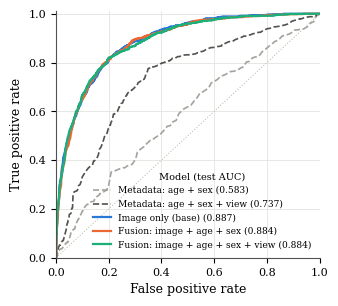

In [14]:
# Fig. A: ROC curves on the RSNA test split
fig, ax = plt.subplots(figsize=(3.4, 3.2))
for name in ORDER:
    fpr, tpr, _ = roc_curve(y_te, results[(name, PRIMARY)]["test"])
    auc = roc_auc_score(y_te, results[(name, PRIMARY)]["test"])
    ax.plot(fpr, tpr, color=COLOR[name], lw=1.6 if name in EXPERIMENTS else 1.2,
            ls="-" if name in EXPERIMENTS else "--", label=f"{NAME[name]} ({auc:.3f})")
ax.plot([0, 1], [0, 1], color="#c3c2b7", lw=0.8, ls=":")
ax.set(xlabel="False positive rate", ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc="lower right", frameon=False, fontsize=6.5, title="Model (test AUC)", title_fontsize=7)
savefig(fig, "fig_roc_test")

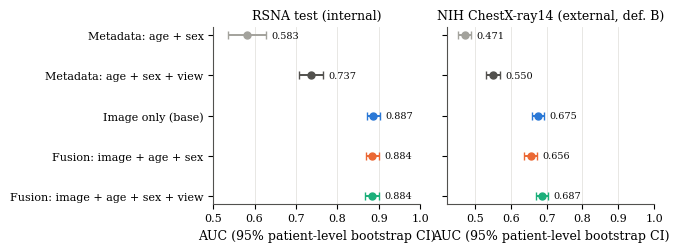

In [15]:
# Fig. B: base vs extended (nested) models - AUC with 95% CI on RSNA test and NIH external
panels = [("RSNA test (internal)", metrics.set_index("model"))]
if HAVE_NIH:
    panels.append(("NIH ChestX-ray14 (external, def. B)",
                   external[external.definition.str.startswith("B")].set_index("model")))
fig, axes = plt.subplots(1, len(panels), figsize=(3.4 * len(panels), 2.6), sharey=False)
axes = np.atleast_1d(axes)
for ax, (title, tab) in zip(axes, panels):
    yy = np.arange(len(ORDER))[::-1]
    for y_, name in zip(yy, ORDER):
        r = tab.loc[name]
        ax.errorbar(r.AUC, y_, xerr=[[r.AUC - r.AUC_lo], [r.AUC_hi - r.AUC]], fmt="o", ms=5,
                    color=COLOR[name], ecolor=COLOR[name], elinewidth=1.4, capsize=3)
        ax.annotate(f"{r.AUC:.3f}", (r.AUC_hi, y_), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=7, color="#0b0b0b")
    ax.set_yticks(yy, [NAME[n] for n in ORDER])
    ax.set_xlabel("AUC (95% patient-level bootstrap CI)")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(min(tab.loc[ORDER].AUC_lo.min() - 0.03, 0.5), 1.0)
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
savefig(fig, "fig_auc_ci")

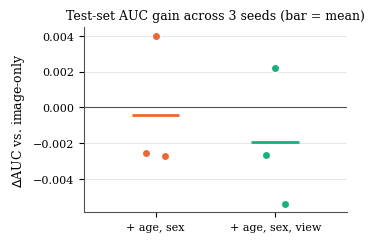

In [16]:
# Fig. C: robustness - AUC gain over the base model for each seed (nested-model comparison)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for k, name in enumerate(["fusion_as", "fusion_asv"]):
    d = seed_df[seed_df.model == name]
    xs = np.full(len(d), k) + np.linspace(-0.08, 0.08, len(d))
    ax.scatter(xs, d.dAUC, s=36, color=COLOR[name], zorder=3, edgecolor="white", linewidth=1)
    ax.hlines(d.dAUC.mean(), k - 0.2, k + 0.2, color=COLOR[name], lw=2)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks([0, 1], ["+ age, sex", "+ age, sex, view"])
ax.set_ylabel(r"$\Delta$AUC vs. image-only")
ax.set_xlim(-0.6, 1.6)
ax.grid(axis="x", visible=False)
ax.set_title(f"Test-set AUC gain across {len(SEEDS)} seeds (bar = mean)")
savefig(fig, "fig_robust_seeds")

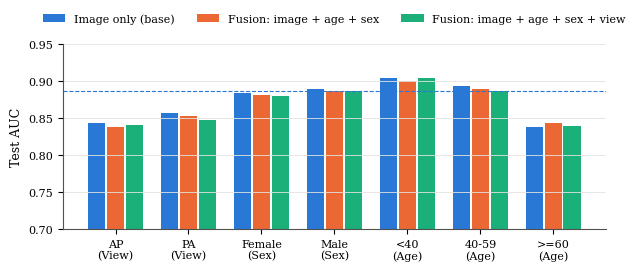

In [17]:
# Fig. D: subgroup AUC (view, sex, age) for base and extended models
sg = subgroup[subgroup.model.isin(list(EXPERIMENTS))]
levels = [(d, l) for d, l, _ in SUBGROUPS]
fig, ax = plt.subplots(figsize=(7.0, 2.4))
w = 0.26
for k, name in enumerate(EXPERIMENTS):
    vals = [sg[(sg.dimension == d) & (sg.level == l) & (sg.model == name)].AUC.iloc[0] for d, l in levels]
    ax.bar(np.arange(len(levels)) + (k - 1) * w, vals, width=w - 0.02, color=COLOR[name], label=NAME[name])
overall = metrics.set_index("model").AUC
ax.axhline(overall["image"], color=COLOR["image"], lw=0.8, ls="--")
ax.set_xticks(np.arange(len(levels)), [f"{l}\n({d})" for d, l in levels])
ax.set_ylim(0.7, 0.95)
ax.set_ylabel("Test AUC")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.22))
savefig(fig, "fig_subgroups")

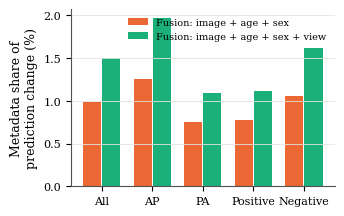

In [18]:
# Fig. E: modality contribution (share of the prediction change attributable to metadata)
fig, ax = plt.subplots(figsize=(3.4, 2.3))
subsets = ["All", "AP", "PA", "Positive", "Negative"]
for k, name in enumerate(["fusion_as", "fusion_asv"]):
    v = contrib[contrib.model == name].set_index("subset").loc[subsets].metadata_share_pct
    ax.bar(np.arange(len(subsets)) + (k - 0.5) * 0.38, v, width=0.36, color=COLOR[name], label=NAME[name])
ax.set_xticks(np.arange(len(subsets)), subsets)
ax.set_ylabel("Metadata share of\nprediction change (%)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=7)
savefig(fig, "fig_modality_share")

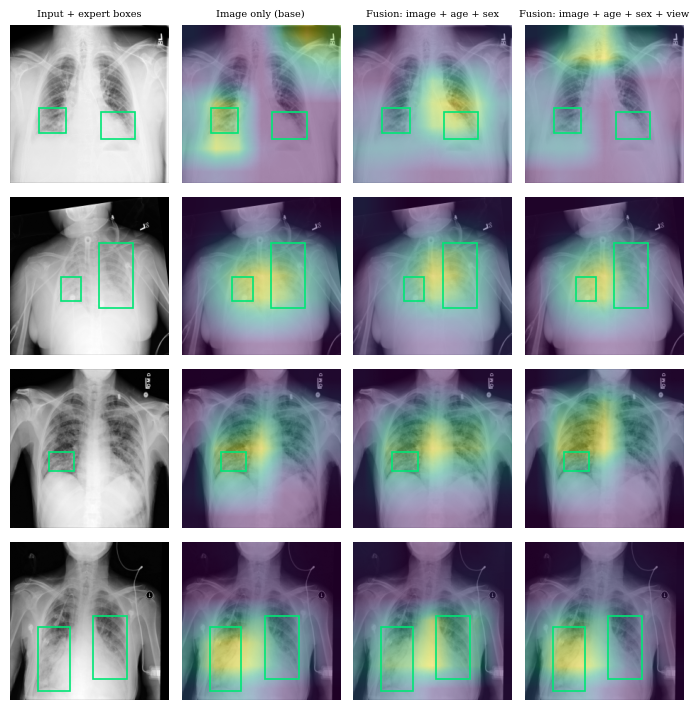

In [19]:
# Fig. F: Grad-CAM examples with radiologist boxes (green)
show = pos_test.sample(4, random_state=PRIMARY).index
names = list(EXPERIMENTS)
fig, axes = plt.subplots(len(show), len(names) + 1, figsize=(7.0, 1.8 * len(show)))
for r_, i in enumerate(show):
    img = np.array(IMAGES[pos_test.row[i]])
    for c in range(len(names) + 1):
        ax = axes[r_, c]
        ax.imshow(img, cmap="gray")
        if c:
            ax.imshow(cams_keep[names[c - 1]][i], cmap="viridis", alpha=0.45)
        for _, b in box_test[box_test.rsna_id == pos_test.rsna_id[i]].iterrows():
            ax.add_patch(patches.Rectangle((b.x * scale, b.y * scale), b.w * scale, b.h * scale,
                                           fill=False, edgecolor="#00e676", lw=1.2))
        if r_ == 0:
            ax.set_title("Input + expert boxes" if c == 0 else NAME[names[c - 1]], fontsize=7)
        ax.axis("off")
plt.tight_layout()
savefig(fig, "fig_gradcam_examples")

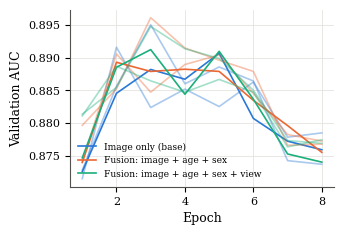

In [20]:
# Fig. G: training curves (validation AUC per epoch, all seeds)
hist = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(3.4, 2.3))
for name in EXPERIMENTS:
    for s, d in hist[hist.model == name].groupby("seed"):
        ax.plot(d.epoch, d.val_auc, color=COLOR[name], lw=1.2, alpha=1 if s == PRIMARY else 0.4,
                label=NAME[name] if s == PRIMARY else None)
ax.set(xlabel="Epoch", ylabel="Validation AUC")
ax.legend(frameon=False, fontsize=6.5)
savefig(fig, "fig_training_curves")

## 12. Export LaTeX tables and number macros for the paper (`tables/`)

In [21]:
def fmt(x, d=3):
    return "--" if pd.isna(x) else f"{x:.{d}f}"


def write(name, text):
    open(f"{TEX}/{name}.tex", "w").write(text)


# Main results table
best = metrics.loc[metrics.model.isin(list(EXPERIMENTS))].set_index("model")
lines = []
for _, r in metrics.iterrows():
    cells = [NAME[r.model], f"{fmt(r.AUC)} [{fmt(r.AUC_lo)}, {fmt(r.AUC_hi)}]"]
    for k in ["Accuracy", "Precision", "Recall", "F1"]:
        v = fmt(r[k])
        cells.append(rf"\textbf{{{v}}}" if r.model in EXPERIMENTS and r[k] == best[k].max() else v)
    cells.append("--" if pd.isna(r.get("dAUC")) else f"{r.dAUC:+.4f} [{r.dAUC_lo:+.4f}, {r.dAUC_hi:+.4f}]")
    cells.append("--" if pd.isna(r.get("DeLong_p")) else fmt(r.DeLong_p))
    lines.append(" & ".join(cells) + r" \\")
write("tab_main_rows", "\n".join(lines))

# Seed robustness rows
seed_lines = []
for m in EXPERIMENTS:
    s_ = seed_summary.loc[m]
    per_seed = " & ".join(fmt(seed_df[(seed_df.model == m) & (seed_df.seed == s)].AUC.iloc[0]) for s in SEEDS)
    gain = "--" if m == "image" else f"{s_.dAUC_mean:+.4f} $\\pm$ {s_.dAUC_sd:.4f}"
    sig = "--" if m == "image" else f"{int(s_.n_sig)}/{len(SEEDS)}"
    seed_lines.append(f"{NAME[m]} & {per_seed} & {fmt(s_.AUC_mean)} $\\pm$ {fmt(s_.AUC_sd)} & {gain} & {sig} \\\\")
write("tab_seed_rows", "\n".join(seed_lines))

# Subgroup rows
piv = subgroup.pivot_table(index=["dimension", "level"], columns="model", values="AUC")
nmap = subgroup.drop_duplicates(["dimension", "level"]).set_index(["dimension", "level"])
TEXLVL = {"<40": "$<$40", "40-59": "40--59", ">=60": r"$\geq$60"}
write("tab_subgroup_rows", "\n".join(
    f"{d} & {TEXLVL.get(l, l)} &{nmap.loc[(d, l), 'n']} & {fmt(100 * nmap.loc[(d, l), 'pos_rate'], 1)} & "
    + " & ".join(fmt(piv.loc[(d, l), m]) for m in ORDER) + r" \\" for d, l, _ in SUBGROUPS))

# Localisation rows
write("tab_loc_rows", "\n".join(
    f"{NAME[r.model]} & {r.n_images} & {fmt(r.energy_in_box)} & {fmt(r.chance_box_area)} & "
    f"{fmt(r.energy_ratio_to_chance, 2)} & {fmt(r.pointing_game)} & {r.wilcoxon_p:.1e} \\\\" for _, r in loc.iterrows()))

# External rows
if HAVE_NIH:
    write("tab_external_rows", "\n".join(
        f"{r.definition.split(':')[0]} & {NAME[r.model]} & {r.n_pos}/{r.n} & {fmt(r.AUC)} [{fmt(r.AUC_lo)}, {fmt(r.AUC_hi)}] & "
        f"{'--' if pd.isna(r.get('dAUC')) else f'{r.dAUC:+.4f}'} & {'--' if pd.isna(r.get('DeLong_p')) else fmt(r.DeLong_p)} \\\\"
        for _, r in external.iterrows()))

# Inline number macros (\newcommand) used in the text
M = metrics.set_index("model")
L = loc.set_index("model")
C = contrib.set_index(["model", "subset"])
mac = {
    "aucTabAS": M.loc["tab_only_as", "AUC"], "aucTabASV": M.loc["tab_only_asv", "AUC"],
    "aucImage": M.loc["image", "AUC"], "aucFusAS": M.loc["fusion_as", "AUC"], "aucFusASV": M.loc["fusion_asv", "AUC"],
    "dAucFusAS": M.loc["fusion_as", "dAUC"], "dAucFusASlo": M.loc["fusion_as", "dAUC_lo"], "dAucFusAShi": M.loc["fusion_as", "dAUC_hi"],
    "pFusAS": M.loc["fusion_as", "DeLong_p"],
    "dAucFusASV": M.loc["fusion_asv", "dAUC"], "dAucFusASVlo": M.loc["fusion_asv", "dAUC_lo"], "dAucFusASVhi": M.loc["fusion_asv", "dAUC_hi"],
    "pFusASV": M.loc["fusion_asv", "DeLong_p"],
    "seedDAucFusAS": seed_summary.loc["fusion_as", "dAUC_mean"], "seedDAucFusASsd": seed_summary.loc["fusion_as", "dAUC_sd"],
    "seedDAucFusASV": seed_summary.loc["fusion_asv", "dAUC_mean"], "seedDAucFusASVsd": seed_summary.loc["fusion_asv", "dAUC_sd"],
    "seedSigFusAS": seed_summary.loc["fusion_as", "n_sig"], "seedSigFusASV": seed_summary.loc["fusion_asv", "n_sig"],
    "shareFusAS": C.loc[("fusion_as", "All"), "metadata_share_pct"], "shareFusASV": C.loc[("fusion_asv", "All"), "metadata_share_pct"],
    "shareFusASVap": C.loc[("fusion_asv", "AP"), "metadata_share_pct"], "shareFusASVpa": C.loc[("fusion_asv", "PA"), "metadata_share_pct"],
    "energyImage": L.loc["image", "energy_in_box"], "energyChance": L.loc["image", "chance_box_area"],
    "pointImage": L.loc["image", "pointing_game"], "nLoc": L.loc["image", "n_images"],
    "cramersV": SCREEN["cramers_v"], "nTest": len(test), "nTrain": len(SPLITS["train"]), "nVal": len(SPLITS["val"]),
}
if HAVE_NIH:
    E = external.set_index(["definition", "model"])
    for tag, d in [("A", "A: Pneumonia"), ("B", "B: Any opacity")]:
        mac[f"extAuc{tag}Image"] = E.loc[(d, "image"), "AUC"]
        mac[f"extAuc{tag}FusAS"] = E.loc[(d, "fusion_as"), "AUC"]
        mac[f"extAuc{tag}FusASV"] = E.loc[(d, "fusion_asv"), "AUC"]
        mac[f"extAuc{tag}TabASV"] = E.loc[(d, "tab_only_asv"), "AUC"]
        mac[f"extN{tag}"] = E.loc[(d, "image"), "n"]
        mac[f"extPos{tag}"] = E.loc[(d, "image"), "n_pos"]


def macro_value(k, v):
    if isinstance(v, (int, np.integer)):
        return str(v)
    if k.endswith("sd"):
        return f"{v:.4f}"
    if k.startswith(("share", "cramers")):
        return f"{v:.2f}"
    if k.startswith(("dAuc", "seedDAuc")) and "sd" not in k:
        return f"{v:+.4f}"
    if k.startswith("pFus"):                       # used as $p\pFusAS$ in the text
        return f"={v:.3f}" if v >= 0.001 else "<0.001"
    return f"{v:.3f}"


write("results_macros", "\n".join(rf"\newcommand{{\{k}}}{{{macro_value(k, v)}}}" for k, v in mac.items()))
write("tab_profile_rows", "\n".join(
    f"{r.Split} & {r.Images} & {r.Patients} & {r['Lung opacity (%)']} & {r['Age mean (SD)']} & {r['Male (%)']} & {r['AP view (%)']} \\\\"
    for _, r in profile.iterrows()))
print(open(f"{TEX}/results_macros.tex").read())
print("\nFiles:", sorted(os.listdir(FIG)), sorted(os.listdir(TEX)))

\newcommand{\aucTabAS}{0.583}
\newcommand{\aucTabASV}{0.737}
\newcommand{\aucImage}{0.887}
\newcommand{\aucFusAS}{0.884}
\newcommand{\aucFusASV}{0.884}
\newcommand{\dAucFusAS}{-0.0025}
\newcommand{\dAucFusASlo}{-0.0088}
\newcommand{\dAucFusAShi}{+0.0035}
\newcommand{\pFusAS}{=0.368}
\newcommand{\dAucFusASV}{-0.0027}
\newcommand{\dAucFusASVlo}{-0.0075}
\newcommand{\dAucFusASVhi}{+0.0021}
\newcommand{\pFusASV}{=0.279}
\newcommand{\seedDAucFusAS}{-0.0004}
\newcommand{\seedDAucFusASsd}{0.0038}
\newcommand{\seedDAucFusASV}{-0.0020}
\newcommand{\seedDAucFusASVsd}{0.0038}
\newcommand{\seedSigFusAS}{1}
\newcommand{\seedSigFusASV}{1}
\newcommand{\shareFusAS}{0.98}
\newcommand{\shareFusASV}{1.50}
\newcommand{\shareFusASVap}{1.97}
\newcommand{\shareFusASVpa}{1.09}
\newcommand{\energyImage}{0.244}
\newcommand{\energyChance}{0.123}
\newcommand{\pointImage}{0.454}
\newcommand{\nLoc}{1082}
\newcommand{\cramersV}{0.36}
\newcommand{\nTest}{4404}
\newcommand{\nTrain}{20401}
\newcommand{\nVal}{4879}
\new